# CaloDiffusion: controlled photon follow-up

This notebook analyzes the **three already-saved fidelity ZIPs**. It does **not** generate new showers or retrain the model.

It does three things:
1. Uses the same fixed reference sample (the seed `20261020` reference split) to compare all three seeds at 8.192, 32.768, and 65.536 GeV.
2. Reconstructs the native-cell geometry for the extreme 65.536 GeV shower and checks how much energy sits in the final layer / outer radial cells.
3. Compares generator-response distributions against the `scale_only` baseline with Wasserstein distance (lower means closer to the fixed reference distribution), plus a bootstrap interval for the difference.

**Cut convention:** the saved fidelity tables use the predeclared 10 MeV (`0.01 GeV`) photon analysis cutoff. This notebook keeps that convention and does not modify the model's generation cutoff.

**Fixed-reference choice:** seed `20261020` contributes the 300-row reference test sample at each energy. That exact sample is reused for all three runs. The generator samples are distribution-compared, not shower-by-shower matched, because the model is conditioned on incident energy rather than the shape of an individual reference shower.

## 1. Load the three saved ZIPs

In Colab, upload the three `validated_calo_smoke_..._fidelity_...zip` files when prompted. If running locally, put the ZIPs in the same folder as this notebook and skip the upload prompt when asked.

In [1]:
from pathlib import Path
import os, glob, json, zipfile, shutil, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wasserstein_distance, ks_2samp

try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

EXPECTED_PATTERN = "validated_calo_smoke_20261024T*_fidelity_*.zip"
local_zips = sorted(Path.cwd().glob(EXPECTED_PATTERN))

if IN_COLAB:
    print("Upload the three fidelity ZIPs from your computer.")
    uploaded = colab_files.upload()
    zip_paths = [Path(name) for name in uploaded if name.endswith(".zip")]
else:
    zip_paths = local_zips
    if not zip_paths:
        raw = input("Folder containing the three fidelity ZIP files (or press Enter to upload/copy them next to this notebook): ").strip()
        if raw:
            zip_paths = sorted(Path(raw).glob(EXPECTED_PATTERN))

if len(zip_paths) != 3:
    raise ValueError(f"Expected exactly 3 fidelity ZIPs, found {len(zip_paths)}. Upload/select the three October 24 fidelity ZIPs.")

WORK = Path.cwd() / "calodiffusion_followup_extracted"
if WORK.exists():
    shutil.rmtree(WORK)
WORK.mkdir(parents=True)

roots = []
for zip_path in zip_paths:
    with zipfile.ZipFile(zip_path) as zf:
        # Guard against unexpected paths in an archive.
        for member in zf.namelist():
            target = (WORK / member).resolve()
            if WORK.resolve() not in target.parents and target != WORK.resolve():
                raise ValueError(f"Unsafe path inside ZIP: {member}")
        zf.extractall(WORK)
    candidates = list(WORK.glob("*/manifest.json"))
    # pick the manifest whose run_tag matches this ZIP's top-level folder name
    with zipfile.ZipFile(zip_path) as zf:
        top = zf.namelist()[0].split("/")[0]
    root = WORK / top
    if not (root / "manifest.json").exists():
        raise FileNotFoundError(f"No manifest found in {zip_path.name}")
    roots.append(root)

runs = {}
for root in roots:
    manifest = json.loads((root / "manifest.json").read_text())
    seed = int(manifest["config"]["seed"])
    if seed in runs:
        raise ValueError(f"Duplicate seed: {seed}")
    runs[seed] = {"root": root, "manifest": manifest,
                  "observables": pd.read_csv(root / "tables" / "photon_all_fidelity_observables.csv"),
                  "partitions": pd.read_csv(root / "tables" / "photon_event_partitions.csv")}

seeds = sorted(runs)
print("Loaded seeds:", seeds)
print("Reference cut overrides:", {s: runs[s]["manifest"].get("analysis_cut_GeV_overrides", {}) for s in seeds})
assert seeds == [20261020, 20261021, 20261022], f"Unexpected seed set: {seeds}"


Upload the three fidelity ZIPs from your computer.


Saving validated_calo_smoke_20261024T154954460325Z_fidelity_20261024T161042404981Z.zip to validated_calo_smoke_20261024T154954460325Z_fidelity_20261024T161042404981Z.zip
Saving validated_calo_smoke_20261024T161135564483Z_fidelity_20261024T163205369907Z.zip to validated_calo_smoke_20261024T161135564483Z_fidelity_20261024T163205369907Z.zip
Saving validated_calo_smoke_20261024T163302893634Z_fidelity_20261024T165425308977Z.zip to validated_calo_smoke_20261024T163302893634Z_fidelity_20261024T165425308977Z.zip
Loaded seeds: [20261020, 20261021, 20261022]
Reference cut overrides: {20261020: {'photon': 0.01, 'pion': 0.01}, 20261021: {'photon': 0.01, 'pion': 0.01}, 20261022: {'photon': 0.01, 'pion': 0.01}}


## 2. Check that the runs are comparable

The checkpoint, repository revision, source hashes, and photon analysis cutoff should match. If any check fails, stop and resolve it before comparing distributions.

In [2]:
check_rows = []
for seed in seeds:
    m = runs[seed]["manifest"]
    check_rows.append({
        "seed": seed,
        "revision": m.get("revision"),
        "checkpoint_sha256": m.get("checkpoints", {}).get("photon", {}).get("sha256"),
        "analysis_cut_GeV": m.get("analysis_cut_GeV_overrides", {}).get("photon"),
        "n_test_per_energy": m.get("config", {}).get("n_test"),
        "generation_repeats": m.get("config", {}).get("generation_repeats"),
    })
compatibility = pd.DataFrame(check_rows)
display(compatibility)

same_checkpoint = compatibility["checkpoint_sha256"].nunique() == 1
same_revision = compatibility["revision"].nunique() == 1
same_cut = compatibility["analysis_cut_GeV"].nunique() == 1 and float(compatibility["analysis_cut_GeV"].iloc[0]) == 0.01
source_hashes = {json.dumps(runs[s]["manifest"].get("source_sha256", {}), sort_keys=True) for s in seeds}
reference_hashes = {runs[s]["manifest"].get("reference_files", {}).get("photon", {}).get("sha256") for s in seeds}
same_sources = len(source_hashes) == 1
same_reference_file = len(reference_hashes) == 1 and None not in reference_hashes
print("Same source file hashes:", same_sources)
print("Same reference-file hash:", same_reference_file)
if not (same_checkpoint and same_revision and same_cut and same_sources and same_reference_file):
    raise ValueError("Runs do not share the same checkpoint/revision/source/reference/cutoff. Do not continue until this is explained.")

REFERENCE_SEED = 20261020  # fixed reference sample for every comparison
ENERGIES = [8.192, 32.768, 65.536]
ENERGY_LABEL = {e: f"{e:g}GeV" for e in ENERGIES}
CUT_GEV = 0.01
print(f"Using seed {REFERENCE_SEED}'s reference test rows as the fixed reference for all runs.")


,seed,revision,checkpoint_sha256,analysis_cut_GeV,n_test_per_energy,generation_repeats
0,20261020,00ebcc3534fc25eee0fe15361483833e0bca34e7,0f77f9c3ed3c9b51b1a61f347960eeb9b859dcdec6cd15...,0.01,300,2
1,20261021,00ebcc3534fc25eee0fe15361483833e0bca34e7,0f77f9c3ed3c9b51b1a61f347960eeb9b859dcdec6cd15...,0.01,300,2
2,20261022,00ebcc3534fc25eee0fe15361483833e0bca34e7,0f77f9c3ed3c9b51b1a61f347960eeb9b859dcdec6cd15...,0.01,300,2


Same source file hashes: True
Same reference-file hash: True
Using seed 20261020's reference test rows as the fixed reference for all runs.


## 3. Compare response to one fixed reference sample

For each energy, the reference is always from seed `20261020` (300 showers). Each seed contributes 600 generator outputs (two repeats across 300 targets) and 300 scale-only outputs.

- `response = deposited energy after the 10 MeV analysis cutoff / incident energy`
- `W1` is the 1-D Wasserstein distance between response distributions; **smaller is closer**.
- The bootstrap resamples reference events and resamples output rows by `target_id`, keeping the two generator repeats for a target together. The CI on `W1(generator) - W1(scale-only)` is especially useful: positive values favor scale-only; negative values favor the generator. If the CI includes zero, treat the difference as inconclusive.

In [3]:
def prepare_groups(df, column):
    # Resample target_id groups; keep repeated generation rows for each target together.
    if "target_id" in df.columns and df["target_id"].notna().all():
        return [g[column].to_numpy(dtype=float) for _, g in df.groupby("target_id", sort=False)]
    return [np.asarray([v], dtype=float) for v in df[column].to_numpy(dtype=float)]


def resample_groups(groups, rng):
    chosen = rng.integers(0, len(groups), size=len(groups))
    return np.concatenate([groups[i] for i in chosen])


def finite(a):
    a = np.asarray(a, dtype=float)
    return a[np.isfinite(a)]


def one_w1_ci(ref_df, sample_df, column="response", n_boot=600, seed=1):
    rng = np.random.default_rng(seed)
    xr = finite(ref_df[column].to_numpy())
    ys = finite(sample_df[column].to_numpy())
    ref_groups = prepare_groups(ref_df, column)
    sample_groups = prepare_groups(sample_df, column)
    point = wasserstein_distance(xr, ys)
    boot = []
    for _ in range(n_boot):
        xb = finite(resample_groups(ref_groups, rng))
        yb = finite(resample_groups(sample_groups, rng))
        if len(xb) and len(yb):
            boot.append(wasserstein_distance(xb, yb))
    lo, hi = np.quantile(boot, [0.025, 0.975]) if len(boot) else (np.nan, np.nan)
    return float(point), float(lo), float(hi)


def paired_method_w1(ref_df, gen_df, scale_df, column="response", n_boot=600, seed=123):
    # Use the same resampled fixed reference draw for W1(generator) and W1(scale-only).
    rng = np.random.default_rng(seed)
    ref_point = finite(ref_df[column].to_numpy())
    gen_point = finite(gen_df[column].to_numpy())
    scale_point = finite(scale_df[column].to_numpy())
    ref_groups = prepare_groups(ref_df, column)
    gen_groups = prepare_groups(gen_df, column)
    scale_groups = prepare_groups(scale_df, column)
    w_gen = wasserstein_distance(ref_point, gen_point)
    w_scale = wasserstein_distance(ref_point, scale_point)
    d_boot, g_boot, s_boot = [], [], []
    for _ in range(n_boot):
        xb = finite(resample_groups(ref_groups, rng))
        gb = finite(resample_groups(gen_groups, rng))
        sb = finite(resample_groups(scale_groups, rng))
        if len(xb) and len(gb) and len(sb):
            wg = wasserstein_distance(xb, gb)
            ws = wasserstein_distance(xb, sb)
            g_boot.append(wg); s_boot.append(ws); d_boot.append(wg - ws)
    d_lo, d_hi = np.quantile(d_boot, [0.025, 0.975]) if d_boot else (np.nan, np.nan)
    g_lo, g_hi = np.quantile(g_boot, [0.025, 0.975]) if g_boot else (np.nan, np.nan)
    s_lo, s_hi = np.quantile(s_boot, [0.025, 0.975]) if s_boot else (np.nan, np.nan)
    return {"W1_generator": w_gen, "W1_generator_lo": g_lo, "W1_generator_hi": g_hi,
            "W1_scale_only": w_scale, "W1_scale_only_lo": s_lo, "W1_scale_only_hi": s_hi,
            "delta_W1_gen_minus_scale": w_gen - w_scale,
            "delta_W1_lo": d_lo, "delta_W1_hi": d_hi}

fixed_obs = runs[REFERENCE_SEED]["observables"]
OUT = Path.cwd() / "calodiffusion_followup_results"
OUT.mkdir(parents=True, exist_ok=True)
comparison_rows = []
delta_rows = []
for energy in ENERGIES:
    stratum = ENERGY_LABEL[energy]
    fixed_ref = fixed_obs[(fixed_obs["stratum"] == stratum) & (fixed_obs["method"] == "reference")].copy()
    assert len(fixed_ref) == 300, f"Expected 300 fixed reference events at {stratum}; got {len(fixed_ref)}"
    for seed in seeds:
        obs = runs[seed]["observables"]
        gen = obs[(obs["stratum"] == stratum) & (obs["method"] == "generator")].copy()
        scale = obs[(obs["stratum"] == stratum) & (obs["method"] == "scale_only")].copy()
        assert len(gen) == 600, f"Expected 600 generator samples at {seed}, {stratum}; got {len(gen)}"
        assert len(scale) == 300, f"Expected 300 scale-only samples at {seed}, {stratum}; got {len(scale)}"
        metrics = paired_method_w1(fixed_ref, gen, scale, n_boot=600, seed=seed + int(energy))
        delta_rows.append({"energy_GeV": energy, "seed": seed, **metrics,
                           "interpretation": ("scale-only closer; interval above zero" if metrics["delta_W1_lo"] > 0 else
                                              "generator closer; interval below zero" if metrics["delta_W1_hi"] < 0 else
                                              "difference inconclusive; interval crosses zero")})
        for method, sample in [("generator", gen), ("scale_only", scale)]:
            point, lo, hi = one_w1_ci(fixed_ref, sample, n_boot=600, seed=seed + int(energy) + (1 if method == "generator" else 2))
            comparison_rows.append({
                "reference_seed_fixed": REFERENCE_SEED, "seed": seed, "energy_GeV": energy,
                "method": method, "n_reference": len(fixed_ref), "n_sample": len(sample),
                "reference_mean": fixed_ref["response"].mean(), "sample_mean": sample["response"].mean(),
                "reference_std": fixed_ref["response"].std(ddof=1), "sample_std": sample["response"].std(ddof=1),
                "mean_difference_sample_minus_ref": sample["response"].mean() - fixed_ref["response"].mean(),
                "std_ratio_sample_over_ref": sample["response"].std(ddof=1) / fixed_ref["response"].std(ddof=1),
                "response_W1": point, "response_W1_lo": lo, "response_W1_hi": hi,
                "KS_statistic": ks_2samp(fixed_ref["response"], sample["response"]).statistic,
                "response_q05": sample["response"].quantile(0.05),
                "response_median": sample["response"].median(),
                "response_q95": sample["response"].quantile(0.95),
            })

comparison = pd.DataFrame(comparison_rows).sort_values(["energy_GeV", "seed", "method"])
display(comparison[["energy_GeV", "seed", "method", "n_reference", "n_sample", "sample_mean", "sample_std", "response_W1", "response_W1_lo", "response_W1_hi"]].round(5))
baseline_comparison = pd.DataFrame(delta_rows).sort_values(["energy_GeV", "seed"])
print("Generator minus scale-only W1; positive means scale-only is closer")
display(baseline_comparison[["energy_GeV", "seed", "W1_generator", "W1_scale_only", "delta_W1_gen_minus_scale", "delta_W1_lo", "delta_W1_hi", "interpretation"]].round(5))
baseline_comparison.to_csv(OUT / "response_baseline_comparison.csv", index=False)

,energy_GeV,seed,method,n_reference,n_sample,sample_mean,sample_std,response_W1,response_W1_lo,response_W1_hi
0,8.192,20261020,generator,300,600,0.91732,0.03779,0.00880,0.00502,0.01324
1,8.192,20261020,scale_only,300,300,0.91471,0.01841,0.01416,0.01147,0.01731
2,8.192,20261021,generator,300,600,0.91741,0.03748,0.00866,0.00502,0.01304
3,8.192,20261021,scale_only,300,300,0.91354,0.02146,0.01463,0.01235,0.01778
4,8.192,20261022,generator,300,600,0.91405,0.03730,0.01143,0.00712,0.01555
5,8.192,20261022,scale_only,300,300,0.91308,0.01997,0.01522,0.01274,0.01813
6,32.768,20261020,generator,300,600,0.96289,0.02171,0.00604,0.00464,0.00781
7,32.768,20261020,scale_only,300,300,0.96772,0.01465,0.00167,0.00130,0.00400
8,32.768,20261021,generator,300,600,0.96488,0.02257,0.00672,0.00547,0.00842
9,32.768,20261021,scale_only,300,300,0.96721,0.01834,0.00237,0.00143,0.00469


Generator minus scale-only W1; positive means scale-only is closer


,energy_GeV,seed,W1_generator,W1_scale_only,delta_W1_gen_minus_scale,delta_W1_lo,delta_W1_hi,interpretation
0,8.192,20261020,0.00880,0.01416,-0.00536,-0.00887,-0.00119,generator closer; interval below zero
1,8.192,20261021,0.00866,0.01463,-0.00597,-0.00991,-0.00180,generator closer; interval below zero
2,8.192,20261022,0.01143,0.01522,-0.00379,-0.00811,0.00030,difference inconclusive; interval crosses zero
3,32.768,20261020,0.00604,0.00167,0.00437,0.00152,0.00604,scale-only closer; interval above zero
4,32.768,20261021,0.00672,0.00237,0.00435,0.00158,0.00637,scale-only closer; interval above zero
5,32.768,20261022,0.00681,0.00110,0.00571,0.00203,0.00780,scale-only closer; interval above zero
6,65.536,20261020,0.00703,0.00334,0.00370,0.00173,0.00538,scale-only closer; interval above zero
7,65.536,20261021,0.00767,0.00296,0.00471,0.00181,0.00599,scale-only closer; interval above zero
8,65.536,20261022,0.00842,0.00245,0.00597,0.00373,0.00721,scale-only closer; interval above zero


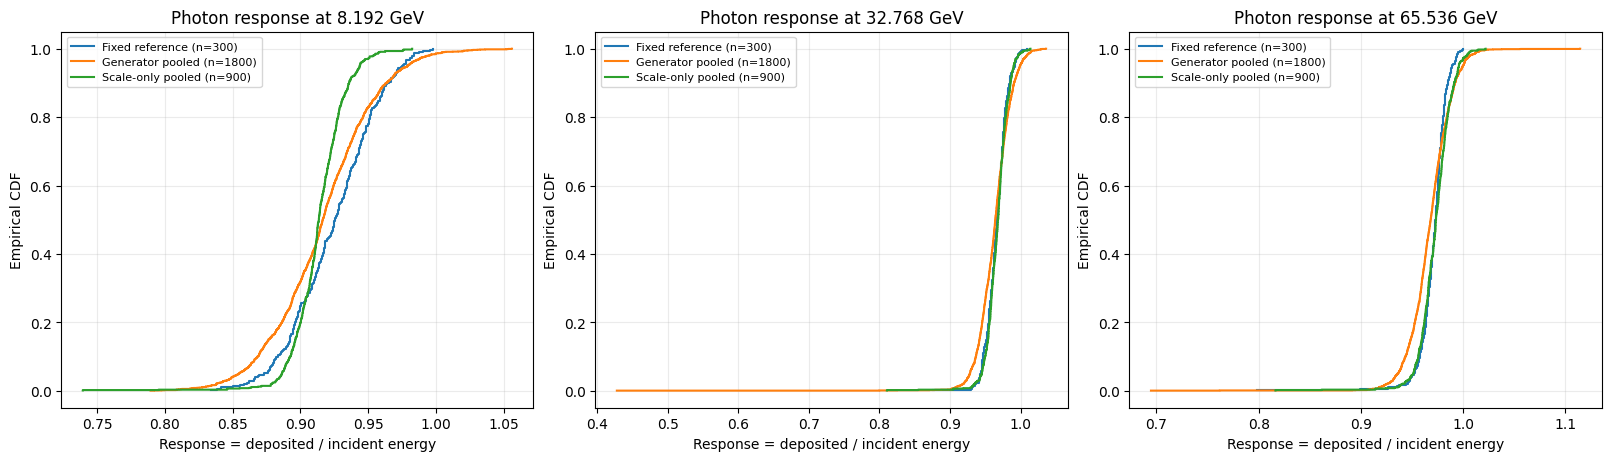

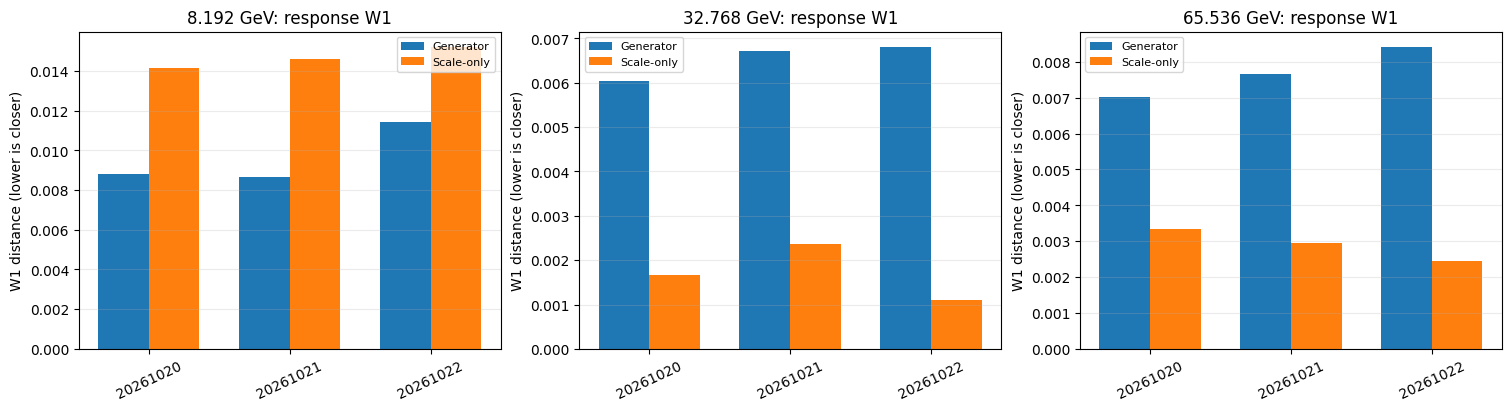

In [4]:
# ECDF curves: one fixed reference distribution, plus the pooled outputs from all three seeds.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
for ax, energy in zip(axes, ENERGIES):
    label = ENERGY_LABEL[energy]
    ref = fixed_obs[(fixed_obs.stratum == label) & (fixed_obs.method == "reference")]["response"].dropna().to_numpy()
    gen_pool, scale_pool = [], []
    for seed in seeds:
        d = runs[seed]["observables"]
        gen_pool.append(d[(d.stratum == label) & (d.method == "generator")]["response"].dropna().to_numpy())
        scale_pool.append(d[(d.stratum == label) & (d.method == "scale_only")]["response"].dropna().to_numpy())
    series = [("Fixed reference (n=300)", ref),
              (f"Generator pooled (n={sum(map(len, gen_pool))})", np.concatenate(gen_pool)),
              (f"Scale-only pooled (n={sum(map(len, scale_pool))})", np.concatenate(scale_pool))]
    for name, vals in series:
        vals = np.sort(vals)
        y = np.arange(1, len(vals)+1) / len(vals)
        ax.step(vals, y, where="post", label=name)
    ax.set_title(f"Photon response at {energy:g} GeV")
    ax.set_xlabel("Response = deposited / incident energy")
    ax.set_ylabel("Empirical CDF")
    ax.grid(True, alpha=0.25)
    ax.legend(fontsize=8)
fig.savefig(OUT / "response_ecdf_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

# Per-seed W1 summary, where lower means closer to the same fixed reference.
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, energy in zip(axes, ENERGIES):
    sub = comparison[comparison.energy_GeV == energy]
    x = np.arange(len(seeds))
    gen = [sub[(sub.seed == s) & (sub.method == "generator")]["response_W1"].iloc[0] for s in seeds]
    scl = [sub[(sub.seed == s) & (sub.method == "scale_only")]["response_W1"].iloc[0] for s in seeds]
    width = 0.36
    ax.bar(x-width/2, gen, width, label="Generator")
    ax.bar(x+width/2, scl, width, label="Scale-only")
    ax.set_xticks(x, [str(s) for s in seeds], rotation=25)
    ax.set_title(f"{energy:g} GeV: response W1")
    ax.set_ylabel("W1 distance (lower is closer)")
    ax.legend(fontsize=8)
    ax.grid(axis="y", alpha=0.25)
fig.savefig(OUT / "response_W1_by_seed.png", dpi=160, bbox_inches="tight")
plt.show()


## 4. Inspect the extreme radial shower

The event ID is `gen:photon:65.536GeV:0:161` in seed `20261021`, generation repeat/run 0. The geometry is reconstructed using the same ordering as the notebook that exported the arrays: within each layer, angular sectors are followed by radial bins. We compare raw deposits with deposits retained at the 10 MeV analysis cutoff.

In [5]:
# OUT was initialized above so the response plots and cell audit share one output folder.

# Find the original native shower by its stable event label.
OUTLIER_SEED = 20261021
OUTLIER_EVENT_ID = "gen:photon:65.536GeV:0:161"
outlier_root = runs[OUTLIER_SEED]["root"]
outlier_found = None
for npz_path in sorted((outlier_root / "arrays").glob("photon_65.536GeV_generator_run*.npz")):
    zz = np.load(npz_path, allow_pickle=False)
    matches = np.where(zz["event_id"].astype(str) == OUTLIER_EVENT_ID)[0]
    if len(matches):
        outlier_found = (npz_path, zz, int(matches[0]))
        break
if outlier_found is None:
    raise FileNotFoundError(f"Could not find {OUTLIER_EVENT_ID} in saved native arrays.")
npz_path, zz, event_idx = outlier_found
native_raw = np.asarray(zz["native"][event_idx], dtype=float)
incident_energy = float(np.asarray(zz["energy"])[event_idx])

geom = json.loads((outlier_root / "photon_geometry.json").read_text())
cell_rows = []
offset = 0
layer_slices = []
for layer_ord, (layer_id, n_angles, edges_list) in enumerate(zip(geom["layer_ids"], geom["n_angles"], geom["radial_edges"])):
    edges = np.asarray(edges_list, dtype=float)
    centers = 0.5 * (edges[:-1] + edges[1:])
    n_radial = len(centers)
    start, stop = offset, offset + int(n_angles) * n_radial
    layer_slices.append(slice(start, stop))
    for angle_idx in range(int(n_angles)):
        for radial_bin, center in enumerate(centers):
            cell_idx = start + angle_idx*n_radial + radial_bin
            cell_rows.append({
                "cell_index": cell_idx, "layer_ordinal": layer_ord, "layer_id": int(layer_id),
                "angle_index": angle_idx, "radial_bin": radial_bin,
                "r_low_XML": edges[radial_bin], "r_high_XML": edges[radial_bin+1],
                "r_center_XML": center,
            })
    offset = stop
cell_map = pd.DataFrame(cell_rows)
if len(native_raw) != len(cell_map):
    raise ValueError(f"Geometry lists {len(cell_map)} cells but native array contains {len(native_raw)} cells")
cell_map["energy_raw_GeV"] = native_raw
cell_map["energy_kept_GeV"] = np.where(native_raw >= CUT_GEV, native_raw, 0.0)
cell_map["fraction_of_kept_energy"] = cell_map["energy_kept_GeV"] / cell_map["energy_kept_GeV"].sum()

kept = cell_map["energy_kept_GeV"].to_numpy()
radius = cell_map["r_center_XML"].to_numpy()
raw_total = native_raw.sum()
kept_total = kept.sum()
weighted_r_rms = np.sqrt(np.sum(kept * radius**2) / kept_total) if kept_total > 0 else np.nan
weighted_r_mean = np.sum(kept * radius) / kept_total if kept_total > 0 else np.nan
print(f"NPZ file: {npz_path.name}")
print(f"Event ID: {OUTLIER_EVENT_ID}")
print(f"Incident energy: {incident_energy:.3f} GeV")
print(f"Raw deposited energy: {raw_total:.6f} GeV; raw response: {raw_total/incident_energy:.6f}")
print(f"Deposited energy kept at 10 MeV cutoff: {kept_total:.6f} GeV; cutoff response: {kept_total/incident_energy:.6f}")
print(f"Cells kept: {(native_raw >= CUT_GEV).sum()} / {len(native_raw)}")
print(f"Recomputed r_rms after cutoff: {weighted_r_rms:.3f} XML radial units; r_mean: {weighted_r_mean:.3f}")

saved_obs = runs[OUTLIER_SEED]["observables"]
saved_obs = saved_obs[saved_obs.event_id == OUTLIER_EVENT_ID][["deposited_GeV", "response", "occupancy", "r_rms", "layer_fraction_4"]]
print("Saved observable row (computed after analysis cutoff):")
display(saved_obs)

layer_summary = cell_map.groupby(["layer_ordinal", "layer_id"], as_index=False).agg(
    raw_energy_GeV=("energy_raw_GeV", "sum"), kept_energy_GeV=("energy_kept_GeV", "sum"))
layer_summary["fraction_of_kept_total"] = layer_summary["kept_energy_GeV"] / kept_total
layer_summary["fraction_of_raw_total"] = layer_summary["raw_energy_GeV"] / raw_total
print("Energy by native layer:")
display(layer_summary.round(5))

# Save every native cell for audit, then display the final-layer cells and the largest deposits.
cell_map.to_csv(OUT / "extreme_shower_all_native_cells.csv", index=False)
print("Final two native layers (IDs 3 and 12):")
display(cell_map[cell_map.layer_id.isin([3, 12])][[
    "cell_index", "layer_id", "angle_index", "radial_bin", "r_low_XML", "r_high_XML", "r_center_XML",
    "energy_raw_GeV", "energy_kept_GeV", "fraction_of_kept_energy"
]].round(5))
print("Largest retained cell deposits:")
display(cell_map.nlargest(15, "energy_kept_GeV")[[
    "cell_index", "layer_id", "angle_index", "radial_bin", "r_low_XML", "r_high_XML", "r_center_XML",
    "energy_raw_GeV", "energy_kept_GeV", "fraction_of_kept_energy"
]].round(5))


NPZ file: photon_65.536GeV_generator_run0.npz
Event ID: gen:photon:65.536GeV:0:161
Incident energy: 65.536 GeV
Raw deposited energy: 59.799182 GeV; raw response: 0.912463
Deposited energy kept at 10 MeV cutoff: 59.552852 GeV; cutoff response: 0.908704
Cells kept: 296 / 368
Recomputed r_rms after cutoff: 416.304 XML radial units; r_mean: 160.659
Saved observable row (computed after analysis cutoff):


,deposited_GeV,response,occupancy,r_rms,layer_fraction_4
4061,59.552852,0.908704,0.804348,416.304024,0.25184


Energy by native layer:


,layer_ordinal,layer_id,raw_energy_GeV,kept_energy_GeV,fraction_of_kept_total,fraction_of_raw_total
0,0,0,0.41722,0.40945,0.00688,0.00698
1,1,1,9.89911,9.74645,0.16366,0.16554
2,2,2,33.47010,33.38805,0.56065,0.55971
3,3,3,1.01495,1.01111,0.01698,0.01697
4,4,12,14.99780,14.99780,0.25184,0.25080


Final two native layers (IDs 3 and 12):


,cell_index,layer_id,angle_index,radial_bin,r_low_XML,r_high_XML,r_center_XML,energy_raw_GeV,energy_kept_GeV,fraction_of_kept_energy
358,358,3,0,0,0.0,50.0,25.0,0.24160,0.24160,0.00406
359,359,3,0,1,50.0,100.0,75.0,0.51888,0.51888,0.00871
360,360,3,0,2,100.0,200.0,150.0,0.13247,0.13247,0.00222
361,361,3,0,3,200.0,400.0,300.0,0.00384,0.00000,0.00000
362,362,3,0,4,400.0,600.0,500.0,0.11816,0.11816,0.00198
363,363,12,0,0,0.0,100.0,50.0,6.03340,6.03340,0.10131
364,364,12,0,1,100.0,200.0,150.0,1.53028,1.53028,0.02570
365,365,12,0,2,200.0,400.0,300.0,1.81934,1.81934,0.03055
366,366,12,0,3,400.0,1000.0,700.0,1.51688,1.51688,0.02547
367,367,12,0,4,1000.0,2000.0,1500.0,4.09790,4.09790,0.06881


Largest retained cell deposits:


,cell_index,layer_id,angle_index,radial_bin,r_low_XML,r_high_XML,r_center_XML,energy_raw_GeV,energy_kept_GeV,fraction_of_kept_energy
363,363,12,0,0,0.0,100.0,50.0,6.03340,6.03340,0.10131
367,367,12,0,4,1000.0,2000.0,1500.0,4.09790,4.09790,0.06881
365,365,12,0,2,200.0,400.0,300.0,1.81934,1.81934,0.03055
364,364,12,0,1,100.0,200.0,150.0,1.53028,1.53028,0.02570
366,366,12,0,3,400.0,1000.0,700.0,1.51688,1.51688,0.02547
282,282,2,6,0,0.0,2.0,1.0,1.14355,1.14355,0.01920
302,302,2,7,1,2.0,5.0,3.5,0.98102,0.98102,0.01647
246,246,2,4,2,5.0,10.0,7.5,0.95169,0.95169,0.01598
263,263,2,5,0,0.0,2.0,1.0,0.86912,0.86912,0.01459
244,244,2,4,0,0.0,2.0,1.0,0.85451,0.85451,0.01435


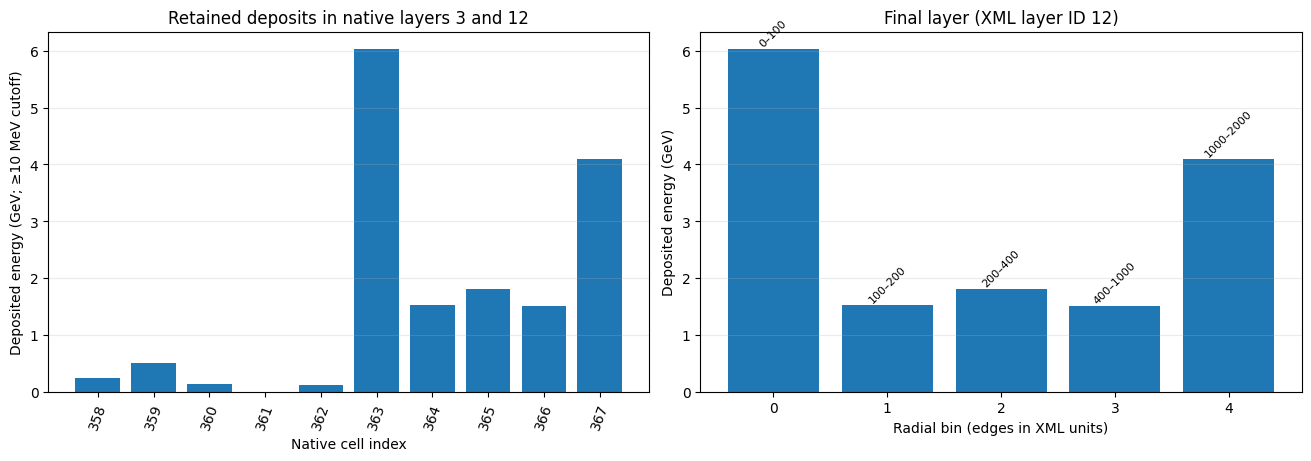

,seed,generation_run,row_index,event_id,r_rms_XML,response,layer12_raw_GeV,layer12_raw_fraction,outermost_cell_raw_GeV,outermost_cell_raw_fraction
761,20261021,0,161,gen:photon:65.536GeV:0:161,416.3040,0.9087,14.9978,0.2508,4.0979,0.0685
656,20261021,0,56,gen:photon:65.536GeV:0:56,141.0356,1.1144,42.2971,0.5768,0.0005,0.0000
961,20261021,1,61,gen:photon:65.536GeV:1:61,118.4594,0.9602,0.3578,0.0057,0.3543,0.0056
393,20261020,1,93,gen:photon:65.536GeV:1:93,114.3686,0.7617,9.0785,0.1810,0.0013,0.0000
1318,20261022,0,118,gen:photon:65.536GeV:0:118,99.8311,0.6946,9.8820,0.2157,0.0000,0.0000
486,20261020,1,186,gen:photon:65.536GeV:1:186,84.6663,0.9346,0.2228,0.0036,0.1564,0.0025
518,20261020,1,218,gen:photon:65.536GeV:1:218,71.7199,1.0067,10.3420,0.1561,0.0000,0.0000
1453,20261022,0,253,gen:photon:65.536GeV:0:253,71.5009,0.9417,0.3115,0.0050,0.0980,0.0016
1027,20261021,1,127,gen:photon:65.536GeV:1:127,66.8418,0.9523,0.2195,0.0035,0.0801,0.0013
960,20261021,1,60,gen:photon:65.536GeV:1:60,66.7990,0.9686,0.3021,0.0047,0.0897,0.0014


In [6]:
# Plot deposits in the last two layers and energy summed by radial bin in each layer.
last_cells = cell_map[cell_map.layer_id.isin([3, 12])].copy()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
axes[0].bar(last_cells["cell_index"].astype(str), last_cells["energy_kept_GeV"])
axes[0].set_title("Retained deposits in native layers 3 and 12")
axes[0].set_xlabel("Native cell index")
axes[0].set_ylabel("Deposited energy (GeV; ≥10 MeV cutoff)")
axes[0].tick_params(axis="x", rotation=70)
axes[0].grid(axis="y", alpha=0.25)

last_layer = cell_map[cell_map.layer_id == 12].sort_values("radial_bin")
axes[1].bar(last_layer["radial_bin"].astype(str), last_layer["energy_kept_GeV"])
axes[1].set_title("Final layer (XML layer ID 12)")
axes[1].set_xlabel("Radial bin (edges in XML units)")
axes[1].set_ylabel("Deposited energy (GeV)")
axes[1].grid(axis="y", alpha=0.25)
for _, row in last_layer.iterrows():
    axes[1].text(str(int(row.radial_bin)), row.energy_kept_GeV, f"{row.r_low_XML:g}–{row.r_high_XML:g}", ha="center", va="bottom", fontsize=8, rotation=45)
fig.savefig(OUT / "extreme_shower_outer_cells.png", dpi=160, bbox_inches="tight")
plt.show()

# Also inspect whether it is isolated: top generated r_rms events and final-layer/outermost fractions.
top_events = []
for seed in seeds:
    root = runs[seed]["root"]
    obs = runs[seed]["observables"]
    obs = obs[(obs.stratum == "65.536GeV") & (obs.method == "generator")].set_index("event_id")
    for path in sorted((root / "arrays").glob("photon_65.536GeV_generator_run*.npz")):
        z = np.load(path, allow_pickle=False)
        run_num = int(path.stem.split("run")[-1])
        for i, arr in enumerate(z["native"]):
            event_id = str(z["event_id"][i])
            row = obs.loc[event_id]
            raw = float(np.sum(arr))
            top_energy = float(arr[-1])
            final_layer_energy = float(np.sum(arr[-5:]))
            top_events.append({
                "seed": seed, "generation_run": run_num, "row_index": i, "event_id": event_id,
                "r_rms_XML": float(row["r_rms"]), "response": float(row["response"]),
                "layer12_raw_GeV": final_layer_energy,
                "layer12_raw_fraction": final_layer_energy/raw if raw > 0 else np.nan,
                "outermost_cell_raw_GeV": top_energy,
                "outermost_cell_raw_fraction": top_energy/raw if raw > 0 else np.nan,
            })
top_events = pd.DataFrame(top_events).sort_values("r_rms_XML", ascending=False)
display(top_events.head(15).round(4))
top_events.to_csv(OUT / "top_radial_tail_generated_events.csv", index=False)


## 5. Compare the radial tail with the fixed reference sample

A large radius in one generated shower is not enough to conclude that the model is wrong. Compare the distribution of final-layer energy fraction and the outermost native-cell energy for the fixed reference sample, the generator, and scale-only outputs. A real shower should not be removed just because it is extreme; first establish how frequently this pattern occurs in the reference.

In [7]:
def native_summary_from_npz(npz_path, cut=0.01):
    z = np.load(npz_path, allow_pickle=False)
    arrays = np.asarray(z["native"], dtype=float)
    records = []
    for i, arr in enumerate(arrays):
        kept_arr = np.where(arr >= cut, arr, 0.0)
        total = kept_arr.sum()
        raw_total = arr.sum()
        final_layer = kept_arr[-5:].sum()  # Geometry check below confirms the final layer has 5 cells.
        outer = kept_arr[-1]
        records.append({
            "event_id": str(z["event_id"][i]),
            "raw_total_GeV": raw_total,
            "kept_total_GeV": total,
            "final_layer_fraction": final_layer/total if total > 0 else np.nan,
            "outermost_cell_GeV": outer,
            "outermost_cell_fraction": outer/total if total > 0 else np.nan,
            "outermost_cell_hit": bool(outer >= cut),
        })
    return pd.DataFrame(records)

# This check depends on the stored geometry: final native layer ID 12 contains exactly 5 cells.
assert int(geom["n_angles"][-1]) * (len(geom["radial_edges"][-1]) - 1) == 5

# Fixed reference native array for each incident energy comes from seed 20261020.
# For the generator/control distributions, use all saved samples from the indicated seed.
radial_rows = []
for energy in ENERGIES:
    label = ENERGY_LABEL[energy]
    # Fixed reference distribution
    ref_path = runs[REFERENCE_SEED]["root"] / "arrays" / f"photon_{label}_reference_run-1.npz"
    ref_rad = native_summary_from_npz(ref_path, CUT_GEV)
    radial_rows.append({
        "energy_GeV": energy, "seed": REFERENCE_SEED, "method": "fixed_reference", "n": len(ref_rad),
        "median_final_layer_fraction": ref_rad.final_layer_fraction.median(),
        "q95_final_layer_fraction": ref_rad.final_layer_fraction.quantile(0.95),
        "max_final_layer_fraction": ref_rad.final_layer_fraction.max(),
        "outermost_cell_hit_rate": ref_rad.outermost_cell_hit.mean(),
        "max_outermost_cell_GeV": ref_rad.outermost_cell_GeV.max(),
    })
    for seed in seeds:
        root = runs[seed]["root"]
        gen_parts, scale_parts = [], []
        for path in sorted((root / "arrays").glob(f"photon_{label}_generator_run*.npz")):
            gen_parts.append(native_summary_from_npz(path, CUT_GEV))
        # scale-only has one saved sample per energy per seed
        scale_path = root / "arrays" / f"photon_{label}_scale_only_run-1.npz"
        scale_parts.append(native_summary_from_npz(scale_path, CUT_GEV))
        for method, d in [("generator", pd.concat(gen_parts, ignore_index=True)),
                          ("scale_only", pd.concat(scale_parts, ignore_index=True))]:
            radial_rows.append({
                "energy_GeV": energy, "seed": seed, "method": method, "n": len(d),
                "median_final_layer_fraction": d.final_layer_fraction.median(),
                "q95_final_layer_fraction": d.final_layer_fraction.quantile(0.95),
                "max_final_layer_fraction": d.final_layer_fraction.max(),
                "outermost_cell_hit_rate": d.outermost_cell_hit.mean(),
                "max_outermost_cell_GeV": d.outermost_cell_GeV.max(),
            })
radial_summary = pd.DataFrame(radial_rows)
print("At 65.536 GeV, compare the final layer and outermost cell with the reference:")
display(radial_summary[radial_summary.energy_GeV == 65.536].round(5))
radial_summary.to_csv(OUT / "radial_tail_reference_comparison.csv", index=False)


At 65.536 GeV, compare the final layer and outermost cell with the reference:


,energy_GeV,seed,method,n,median_final_layer_fraction,q95_final_layer_fraction,max_final_layer_fraction,outermost_cell_hit_rate,max_outermost_cell_GeV
14,65.536,20261020,fixed_reference,300,0.00130,0.00818,0.18018,0.02000,0.09881
15,65.536,20261020,generator,600,0.00124,0.00599,0.18184,0.01500,0.15643
16,65.536,20261020,scale_only,300,0.00064,0.00510,0.02354,0.01667,0.56022
17,65.536,20261021,generator,600,0.00122,0.00698,0.57915,0.02000,4.09790
18,65.536,20261021,scale_only,300,0.00070,0.00552,0.19888,0.02000,0.20833
19,65.536,20261022,generator,600,0.00128,0.00798,0.21703,0.01167,0.09804
20,65.536,20261022,scale_only,300,0.00077,0.00598,0.19888,0.02667,0.56022


## 6. Save the outputs and interpret the checks

The result folder contains CSV tables and PNG figures. Interpret the response check using the **same fixed reference** throughout. Do not conclude that the model should be retrained from response alone: this analysis tests one observable and a simple scale-only baseline, not full shower quality.

In [8]:
# Save the comparison table and a concise machine-readable run summary.
comparison.to_csv(OUT / "fixed_reference_response_comparison.csv", index=False)
baseline_comparison.to_csv(OUT / "response_baseline_comparison.csv", index=False)
compatibility.to_csv(OUT / "run_compatibility.csv", index=False)

summary_lines = [
    f"Fixed reference seed: {REFERENCE_SEED}",
    f"Seeds compared: {seeds}",
    f"Photon analysis cutoff: {CUT_GEV} GeV (10 MeV)",
    "W1 means Wasserstein distance between response distributions; lower is closer.",
    "For delta_W1_gen_minus_scale, positive favors scale-only; negative favors generator.",
    "Check whether the bootstrap interval for delta_W1 crosses zero before describing one method as clearly closer.",
    f"Extreme shower: {OUTLIER_EVENT_ID}",
    f"Raw deposit: {raw_total:.6f} GeV; retained deposit: {kept_total:.6f} GeV; recomputed r_rms: {weighted_r_rms:.3f} XML units.",
]
(OUT / "README_results.txt").write_text("\n".join(summary_lines) + "\n")

bundle = Path.cwd() / "CaloDiffusion_Followup_Results.zip"
with zipfile.ZipFile(bundle, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for p in OUT.rglob("*"):
        if p.is_file():
            zf.write(p, arcname=f"calodiffusion_followup_results/{p.relative_to(OUT)}")
print("Results saved to:", OUT)
print("ZIP bundle:", bundle)
print("Key files: fixed_reference_response_comparison.csv, response_baseline_comparison.csv, top_radial_tail_generated_events.csv, radial_tail_reference_comparison.csv, extreme_shower_all_native_cells.csv")
if IN_COLAB:
    colab_files.download(str(bundle))


Results saved to: /content/calodiffusion_followup_results
ZIP bundle: /content/CaloDiffusion_Followup_Results.zip
Key files: fixed_reference_response_comparison.csv, response_baseline_comparison.csv, top_radial_tail_generated_events.csv, radial_tail_reference_comparison.csv, extreme_shower_all_native_cells.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Decision guide

- **Common reference:** all three seed comparisons use the same 300 reference events at each energy; do not substitute each run's own `reference` table after this point.
- **Extreme shower:** the saved observable should agree with the recomputed `r_rms` after the same threshold. The last five native cells must map to XML layer ID 12 and radial bins [0,100], [100,200], [200,400], [400,1000], [1000,2000]. If those checks pass, the high RMS is driven by the actual saved deposit pattern; compare its frequency with reference tails before classifying it as physics/model failure.
- **Scale-only baseline:** at 32.768 and 65.536 GeV, compare generator and scale-only W1 for each seed. If the `delta_W1_gen_minus_scale` interval is above zero, scale-only is closer for response on this fixed sample. This means the generator's response distribution is worse than this simple baseline on that observable; it does not mean scale-only is a better shower generator overall.
- **Next action:** investigate the outer-layer tail and response mismatch first. Do not retrain or change cutoffs solely to make agreement look better.